# 04 · How data goes wrong

*Breaking good data on purpose so I know exactly what a QA check should find.*

Notebook 03 found two broken sensors just by looking. Susanville reported −39 °C in September and a naval airfield on the coast kept reporting 2 °F. Those were easy because they were huge. The faults that actually hurt a model are the quiet ones, like a thermometer that reads 1 °C warm after a sensor swap or one that slowly drifts as it ages. Nobody spots those by eye and nobody hands you a list of them.

That's a problem for building QA checks. To know how good a check is I need to know how many real problems it misses and I can't count misses without a list of what's really wrong. So this notebook makes that list. I take stations I trust, break copies of some of them in controlled ways and write down exactly what I broke, where, when and by how much. Notebook 05 then runs its checks on this data and gets scored against the list.

By the end I'll have a dataset of about 3.7 million station-hours where every hour carries a label saying whether it's faulty and why. We'll also see six kinds of fault up close. Some of them jump out once you look at the difference from HRRR. Others hide almost perfectly and those are the useful ones to know about before writing any checks.

## Why plant faults at all

Two numbers describe how good a check is. **Recall** is the share of real faults it catches. **Precision** is the share of its alarms that point at real faults. A check that flags everything has perfect recall and useless precision. A check that flags nothing never raises a false alarm and catches nothing.

Precision can be estimated on real data by checking a sample of alarms by hand. Recall can't because you'd have to know about the faults the check missed. Planting faults solves that. I know every fault so I can count exactly which ones were found.

Planting also lets me control the size of each fault. Whether a check catches a 0.5 °C step or a 3 °C step is a very different question so instead of one recall number I'll get recall against fault size. That's a much more honest answer than "the check catches 80% of faults" which mostly depends on how big you chose to make them.

The catch is that planted faults are only as realistic as I make them. Each type below imitates something that really happens to stations, with sizes taken from what's been published about real networks. And the same checks will also run on the real data in notebook 05 because planted faults can't tell me what the real data is hiding.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from wxlab import stations as st, reference as ref, faults as fl

plt.rcParams["figure.dpi"] = 80
YEARS = range(2021, 2025)
REF_DIR = Path(DATA_DIR) / "reference"

# The matched table from notebook 03: every station-hour next to the height-corrected HRRR value.
reference = ref.load(REF_DIR / "hrrr")
model_elev = pd.read_parquet(REF_DIR / "hrrr_model_elevation.parquet").set_index("station_id").model_elevation_m
hourly = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", years=YEARS)
matched = ref.match(hourly, reference, model_elev)
history = st.load_station_history(Path(DATA_DIR) / "meta").set_index("station_id")
print(f"{len(matched):,} matched station-hours at {matched.station_id.nunique()} stations")

5,249,635 matched station-hours at 165 stations


## Step 1 · Choosing stations I trust

Planting a fault into a station that's already broken would make a mess. If a check flagged it I couldn't tell whether it found the planted fault or the real one and every real fault in an "untouched" station would count as a false alarm. So I start with a **baseline**: stations where I can't see anything wrong.

`fl.select_baseline` keeps a station if four things hold over 2021–2024:

- **It's nearly complete.** At least 90% of hours have both a temperature and an HRRR value.
- **Its difference from HRRR is steady.** The monthly mean of station minus HRRR moves by at most 0.6 °C (as a standard deviation) over the four years. Notebook 03 showed the median station moves by about 0.38 °C.
- **It has almost no gross errors.** At most 24 hours where the station and HRRR disagree by more than 15 °C.
- **It isn't a duplicate of another station.** More on that below.

This lowers the chance of hidden real faults but can't remove it. "Baseline" means "nothing I can see" and not "certainly clean". Any hidden fault left in the baseline will show up in notebook 05 as an apparent false alarm which is something to keep in mind when reading precision.

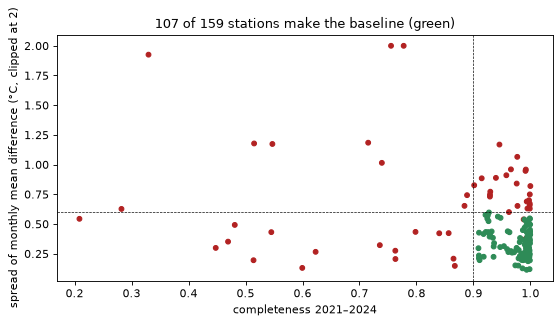

                                                name  completeness  monthly_spread  gross_hours
station_id                                                                                     
72290993115               NAVAL AUXILIARY LANDING FD          0.78            5.42         1818
72583799999                          SUSANVILLE MUNI          0.76            5.34          282
72292800369   MCOLF CAMP PENDLETON RED BEACH AIRPORT          0.33            1.93            5
72292593117                 NALF/F. SHERMAN FLD ARPT          0.72            1.18            2
A0705300346                   TRINITY CENTER AIRPORT          0.52            1.18            0
72493723289  PALO ALTO AIRPORT OF SANTA CLARA COUNTY          0.55            1.17            0
72065200433               BRIDGEPORT SONORA JUNCTION          0.95            1.17            2
72292023191                         CATALINA AIRPORT          0.98            1.07            9
99773499999                             

In [3]:
stats = fl.select_baseline(matched).join(history["name"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(stats.completeness, stats.monthly_spread.clip(upper=2), c=np.where(stats.baseline, "seagreen", "firebrick"), s=18)
ax.axvline(fl.MIN_COMPLETENESS, color="k", lw=0.6, ls="--"); ax.axhline(fl.MAX_MONTHLY_SPREAD, color="k", lw=0.6, ls="--")
ax.set(xlabel="completeness 2021–2024", ylabel="spread of monthly mean difference (°C, clipped at 2)",
       title=f"{stats.baseline.sum()} of {len(stats)} stations make the baseline (green)")
plt.show()
cols = ["name", "completeness", "monthly_spread", "gross_hours"]
print(stats[~stats.baseline].sort_values("monthly_spread", ascending=False)[cols].head(12).round(2).to_string())

About two thirds of the stations make it. The rest fail mostly for being incomplete or unsteady and the top of the reject list is exactly where notebook 03 pointed. The naval airfield and Susanville are there with their gross errors. Camp Pendleton's record is mostly missing. Catalina, Bridgeport, Big Bear and Mount Shasta are out for being unsteady. That's the marine layer and cold valleys from notebook 03 (honest physics) that still makes them a poor background for planting a 0.5 °C fault.

Notice the trade-off. A stricter baseline is cleaner but smaller and it leans toward easy, well-behaved stations so checks tuned on it might look better than they'll do in the wild. The thresholds here are a judgement call and they're written down in `wxlab.faults` so they can be changed and rerun.

### Two stations that are really one

While building this notebook a coincidence led somewhere. Some pairs of stations have nearly identical temperature records. Nearby stations are always highly correlated but two independent thermometers almost never report the *same* value hour after hour. `fl.duplicate_pairs` looks for pairs that do.

In [4]:
dups = fl.duplicate_pairs(matched)
dups.assign(name_a=dups.station_a.map(history["name"]), name_b=dups.station_b.map(history["name"])).round(3)

,station_a,station_b,overlap_hours,identical_share,name_a,name_b
0,72286699999,99999923122,29508,0.995,SAN BERNARDINO INTL,NORTON AAF
1,72594024213,72594524283,7310,1.000,WOODLEY ISLAND (NEW 10/94),ARCATA AIRPORT


Two pairs are the same station under two ids. Norton Air Force Base closed in the 1990s and its airfield became San Bernardino International. ISD carries both ids with 99.5% identical values. Woodley Island and Arcata Airport match on essentially every hour they share so one id is republishing the other's reports.

That matters more than it looks. In notebook 05 a duplicate would make a perfect "neighbour" that always agrees so a fault would seem confirmed or cleared by what's really the same sensor. In notebook 09 a held-out station whose twin sits in the training data would leak the answer. The baseline keeps the more complete id of each pair and drops the other. Neither dropped id would have made the baseline anyway this time but the guard stays for the next dataset.

## Step 2 · Keeping a clean test set

Notebook 09 trains a model on this data and tests it so I decide now what the test set is and keep faults out of it entirely.

- **2024 stays clean everywhere.** Faults only go into 2021–2023.
- **21 held-out stations (20% of the baseline) never get a fault.** They let notebook 09 test whether a model works at stations it never trained on.

Then about 25% of the baseline stations get one fault each. The other three quarters stay untouched so a check can raise false alarms on them. Real networks look like that. Most stations are fine most of the time and a test set where every station is broken would make precision meaningless.

In [5]:
planted, catalogue, stats, holdout = fl.make(matched, seed=0)
catalogue["name"] = catalogue.station_id.map(history["name"])
print(f"baseline {stats.baseline.sum()} stations · held out {len(holdout)} · faulty {len(catalogue)} "
      f"· {len(planted):,} station-hours")
print("faults per type:", catalogue.fault_type.value_counts().to_dict())
catalogue[["fault_id", "name", "fault_type", "fault_size", "unit", "start", "end", "affected_hours"]].assign(
    start=lambda c: c.start.dt.strftime("%Y-%m-%d"), end=lambda c: c.end.dt.strftime("%Y-%m-%d"))

baseline 107 stations · held out 21 · faulty 27 · 3,683,541 station-hours
faults per type: {'drift': 5, 'bias': 5, 'step': 5, 'time_offset': 4, 'stuck': 4, 'storm_gaps': 4}


,fault_id,name,fault_type,fault_size,unit,start,end,affected_hours
0,0,POINT MUGU,time_offset,1.0,hours,2023-01-03,2023-11-30,5538
1,1,SALINAS MUNICIPAL AIRPORT,drift,-3.0,°C at the end of the drift,2021-04-09,2022-06-10,9753
2,2,STOCKTON METROPOLITAN AIRPORT,bias,-1.0,°C,2021-01-01,2024-01-01,26261
3,3,VAN NUYS AIRPORT,bias,0.5,°C,2021-01-01,2024-01-01,26249
4,4,NRTHORP FLD/HATHRN MUNI AP,stuck,6.0,hours,2023-07-29,2023-07-29,5
5,5,TWENTY NINE PALMS,storm_gaps,0.5,share of storm hours removed,2021-01-01,2024-01-01,350
6,6,RED BLUFF MUNICIPAL ARPT,time_offset,8.0,hours,2023-01-07,2023-10-18,6627
7,7,REDDING MUNICIPAL AIRPORT,bias,-2.0,°C,2021-01-01,2024-01-01,26149
8,8,ROHNERVILLE AIRPORT,bias,2.0,°C,2021-01-01,2024-01-01,23529
9,9,BICYCLE LAKE FORT IRWIN AAF,bias,-3.0,°C,2021-01-01,2024-01-01,25254


That's the **fault catalogue**, the answer key notebook 05 gets scored against. Each faulty station has one fault so any detection can be pinned on one cause. Fault types are dealt out evenly and sizes are drawn from a grid for each type. Besides the planned start and end the catalogue records the first and last hour each fault actually touches and how many hours it affects because a planned start can land in a real outage. Notebook 05 scores against the hours the fault actually touched.

The planted table keeps every row. The true values stay in `air_temperature_true` and `dew_point_temperature_true`. The observed values (what a pipeline would see) go in `air_temperature` and `dew_point_temperature` and every row gets a `fault_id`, `fault_type` and `is_faulty` label. Nothing is deleted. A planted gap just sets the observed value to missing.

Now let's look at each fault type in turn. For each one we'll see it in the raw temperature and in the difference from HRRR, plus why it would mislead a model.

## Step 3 · A step

A **step** is a sudden jump in the reading that then stays. It's what an instrument swap or a recalibration or a station move looks like. When the US cooperative network switched from liquid thermometers to electronic sensors in the 1980s the switch shifted daily maxima by about −0.4 °C and minima by about +0.3 °C (Quayle et al. 1991). Steps of a few tenths of a degree up to about 1 °C are typical of real station changes. The grid goes from 0.5 to 3 °C in either direction.

Here's Corona's airport with a planted step of +1 °C from 28 March 2023.

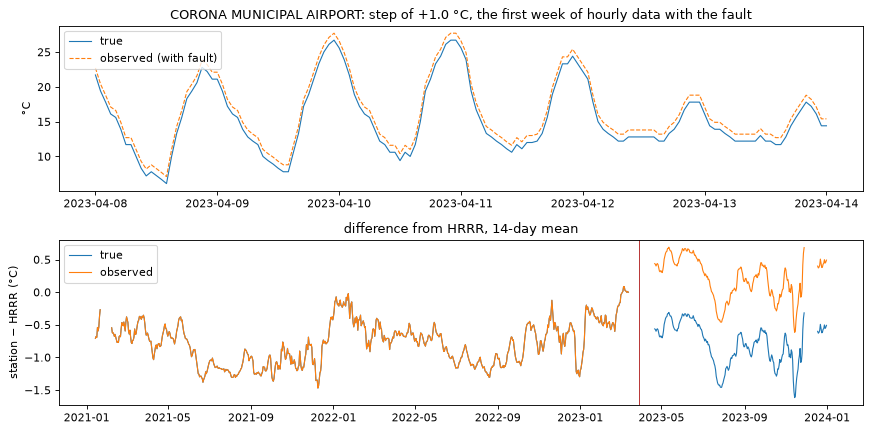

In [6]:
def one(fault_type, size):
    f = catalogue[(catalogue.fault_type == fault_type) & (catalogue.fault_size == size)].iloc[0]
    return f, planted[planted.station_id == f.station_id].set_index("time")

f, s = one("step", 1.0)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))
w = s[f.first_affected - pd.Timedelta("1D"): f.first_affected + pd.Timedelta("6D")]
axes[0].plot(w.index, w.air_temperature_true, lw=1, label="true")
axes[0].plot(w.index, w.air_temperature, lw=1, ls="--", label="observed (with fault)")
axes[0].set_ylabel("°C"); axes[0].legend(loc="upper left")
axes[0].set_title(f"{f['name']}: step of {f.fault_size:+.1f} °C, the first week of hourly data with the fault")
daily = s[["diff_air_temperature"]].assign(true=s.air_temperature_true - s.hrrr_air_temperature_adj).resample("D").mean()
daily = daily[:"2023-12-31"]
axes[1].plot(daily.index, daily.true.rolling(14).mean(), lw=1, label="true")
axes[1].plot(daily.index, daily.diff_air_temperature.rolling(14).mean(), lw=1, label="observed")
axes[1].axvline(f.start, color="firebrick", lw=0.8); axes[1].set_ylabel("station − HRRR (°C)")
axes[1].set_title("difference from HRRR, 14-day mean"); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

There's a bonus lesson in the bottom panel. Corona's real record has a month-long gap from about 10 March to 8 April 2023 and the planted step date landed inside it so the step shows up when the data comes back. That's realistic. Sensors often get swapped during an outage so a step right after a gap is a classic pattern.

In the raw temperature the step is lost. The daily cycle swings by 15 °C or more and a 1 °C shift just slides the line up a little. Nobody would see it and no range check would catch it.

In the difference from HRRR it's a clear jump on the right date. That's the whole idea from notebook 03 working. Subtract the weather and a small, lasting change stands out. A changepoint check on this series should find it and how small a step it can find is one of the main things notebook 05 measures.

**Why it misleads a model.** A model trained across the step learns a blend of two different sensors. It'll be a bit wrong before and after and if the step sits at the end of the training period the model learns the faulty version as "normal" for that station.

## Step 4 · A slow drift

A **drift** is an error that grows a little every day. Ageing sensors and dirty radiation shields drift and the error usually grows until someone replaces the sensor. The drifts ramp linearly from zero to their full size over six to eighteen months and then reset.

Here's San Jose's airport drifting to +1 °C over a year.

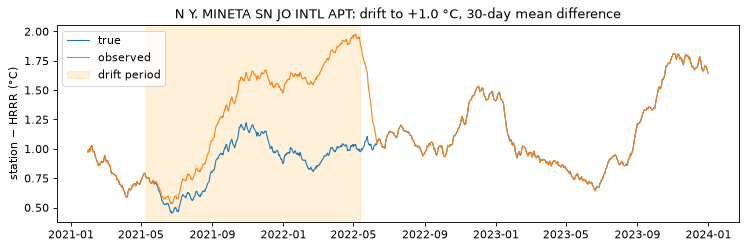

In [7]:
f, s = one("drift", 1.0)
daily = s[["diff_air_temperature"]].assign(true=s.air_temperature_true - s.hrrr_air_temperature_adj).resample("D").mean()[:"2023-12-31"]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(daily.index, daily.true.rolling(30).mean(), lw=1, label="true")
ax.plot(daily.index, daily.diff_air_temperature.rolling(30).mean(), lw=1, label="observed")
ax.axvspan(f.start, f.end, color="orange", alpha=0.15, label="drift period")
ax.set(ylabel="station − HRRR (°C)", title=f"{f['name']}: drift to {f.fault_size:+.1f} °C, 30-day mean difference")
ax.legend(loc="upper left"); plt.show()

A drift is harder than a step even in the difference series. There's no single date where something happens and over a year the true difference wanders by a few tenths of a degree with the seasons anyway. You can see the observed line pull away from the true one and then snap back when the "sensor gets replaced". The snap back is often easier to detect than the drift itself because it's a step.

**Why it misleads a model.** A drifting station teaches the model a slowly changing relationship that doesn't exist. Worse, drift is easy to mistake for real climate change at one place which is the exact signal a climate dataset is supposed to preserve.

## Step 5 · A constant bias

A **bias** here is an offset that's there from day one and never changes, like a sensor mounted too close to a parking lot. Here's Stockton's airport reading 1 °C cold for all of 2021–2023.

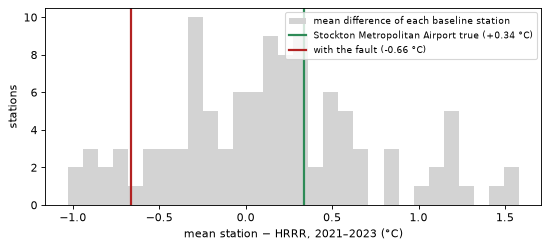

In [8]:
f, s = one("bias", -1.0)
per_station = matched.groupby("station_id").diff_air_temperature.mean()
per_station = per_station[per_station.index.isin(stats.index[stats.baseline])]
obs = s[:"2023-12-31"].diff_air_temperature.mean()
true = (s.air_temperature_true - s.hrrr_air_temperature_adj)[:"2023-12-31"].mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(per_station, bins=30, color="lightgray", label="mean difference of each baseline station")
ax.axvline(true, color="seagreen", lw=2, label=f"{f['name'].title()} true ({true:+.2f} °C)")
ax.axvline(obs, color="firebrick", lw=2, label=f"with the fault ({obs:+.2f} °C)")
ax.set(xlabel="mean station − HRRR, 2021–2023 (°C)", ylabel="stations"); ax.legend(fontsize=8); plt.show()

There's nothing to see here and that's the point. With the fault Stockton's mean difference still sits well inside the range of honest stations. A bias that's been there from the start has no "before" to compare against so it looks exactly like the representativeness error from notebook 03. A coastal station 1 °C warm because its grid box is half water and a station 1 °C warm because of a bad sensor give the same number.

I plant biases anyway so I can measure that honestly. I expect checks to mostly miss them. Catching them takes outside information like station metadata, a site visit or a really close neighbour and notebook 05 will test the neighbour route.

**Why it misleads a model.** A model trained on a biased station learns the bias as part of that place's climate. Every prediction for that station is off by the bias and nothing in the data says so.

## Step 6 · A stuck sensor

A **stuck** sensor keeps reporting the same value. Here's Beale Air Force Base stuck for three days.

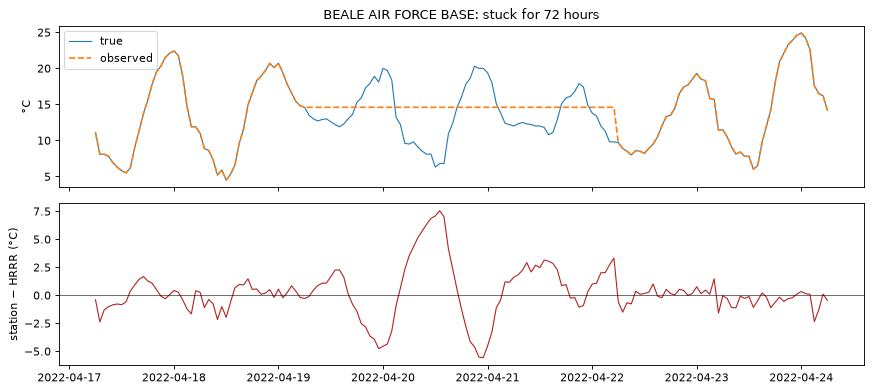

longest run of one repeated value in the CLEAN baseline data: median 13 hours, max 36 hours


In [9]:
f, s = one("stuck", 72.0)
w = s[f.start - pd.Timedelta("2D"): f.end + pd.Timedelta("2D")]
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(w.index, w.air_temperature_true, lw=1, label="true")
axes[0].plot(w.index, w.air_temperature, lw=1.5, ls="--", label="observed")
axes[0].set_ylabel("°C"); axes[0].legend(loc="upper left")
axes[0].set_title(f"{f['name']}: stuck for {f.fault_size:.0f} hours")
axes[1].plot(w.index, w.diff_air_temperature, lw=1, color="firebrick")
axes[1].axhline(0, color="k", lw=0.5); axes[1].set_ylabel("station − HRRR (°C)")
plt.tight_layout(); plt.show()

def longest_repeat(x):
    x = x.dropna()
    return (x != x.shift()).cumsum().value_counts().max()
runs = matched[matched.station_id.isin(stats.index[stats.baseline])].groupby("station_id").air_temperature.apply(longest_repeat)
print(f"longest run of one repeated value in the CLEAN baseline data: median {runs.median():.0f} hours, max {runs.max():.0f} hours")

Three days stuck is obvious. The flat line ignores the daily cycle and the difference from HRRR swings with the weather it's missing.

Short stuck periods are another story. The printout shows that healthy stations already repeat one value for many hours. Most airports report whole degrees Fahrenheit (notebook 01) and on a calm cloudy night or in a foggy morning the temperature can sit on one value for half a day. So a 6-hour stuck fault looks exactly like a quiet night. A stuck check has to look for a value that stays flat *while HRRR says the temperature should be moving*.

**Why it misleads a model.** A stuck sensor gives the model a run of wrong targets that are all identical which teaches it that the temperature can ignore the weather. It's a small effect for a few hours and a big one for a week.

## Step 7 · A time offset

A **time offset** keeps every value correct but labels it with the wrong hour. A classic version is a station or a data feed that records local time and gets read as UTC. In California that shifts everything by 8 hours. Here's Red Bluff's airport with an 8-hour offset.

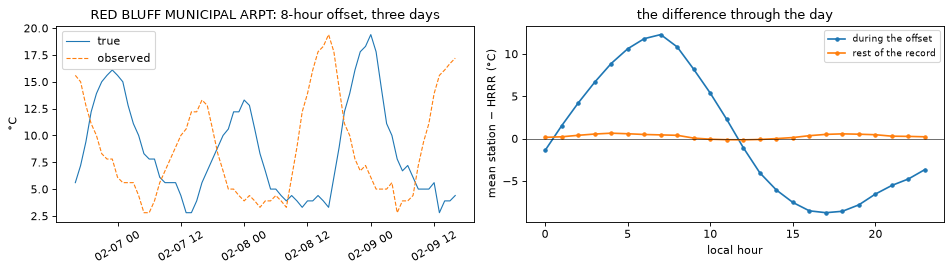

during the offset: mean difference +0.33 °C but RMSE 8.1 °C (rest of record RMSE 1.1 °C)


In [10]:
f, s = one("time_offset", 8.0)
inside = (s.index >= f.start) & (s.index < f.end)
w = s[f.start + pd.Timedelta("30D"): f.start + pd.Timedelta("33D")]
local_hour = s.index.tz_convert("America/Los_Angeles").hour
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(w.index, w.air_temperature_true, lw=1, label="true")
axes[0].plot(w.index, w.air_temperature, lw=1, ls="--", label="observed")
axes[0].set_ylabel("°C"); axes[0].legend(loc="upper left"); axes[0].set_title(f"{f['name']}: 8-hour offset, three days")
axes[0].tick_params(axis="x", rotation=30)
axes[1].plot(s[inside].groupby(local_hour[inside]).diff_air_temperature.mean(), marker=".", label="during the offset")
axes[1].plot(s[~inside].groupby(local_hour[~inside]).diff_air_temperature.mean(), marker=".", label="rest of the record")
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set(xlabel="local hour", ylabel="mean station − HRRR (°C)", title="the difference through the day")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
d_in = s[inside].diff_air_temperature
print(f"during the offset: mean difference {d_in.mean():+.2f} °C but RMSE {np.sqrt((d_in ** 2).mean()):.1f} °C "
      f"(rest of record RMSE {np.sqrt((s[~inside].diff_air_temperature ** 2).mean()):.1f} °C)")

This one is sneaky in a specific way. The mean difference barely changes because every value is still a real temperature from that station and the warm and cold hours cancel out. A check that only watches the average would see nothing. But plot the difference by hour of day and it's a wild ±10 °C swing. The afternoon peak shows up labelled as early morning.

That's why notebook 03's finding matters. The difference has a normal daily cycle for each station and a check that compares each hour against the normal for that hour catches this instantly. A 1-hour offset is much subtler. It moves the morning warm-up by one hour which at a coastal station is a fraction of a degree.

**Why it misleads a model.** The model pairs HRRR's afternoon with the station's night. It learns a scrambled relationship between the inputs and the target. In ML language this is feature–label misalignment and it can quietly wreck a model while every value passes every range check.

## Step 8 · Gaps in storms

The last fault doesn't change any value. **Storm gaps** remove values during storms which is when power and communications fail in real life. A storm hour here is a station's windiest 2% of hours or any hour with at least 1 mm of rain. That's about 3% of hours. Here's Columbia's airport losing 90% of its storm hours.

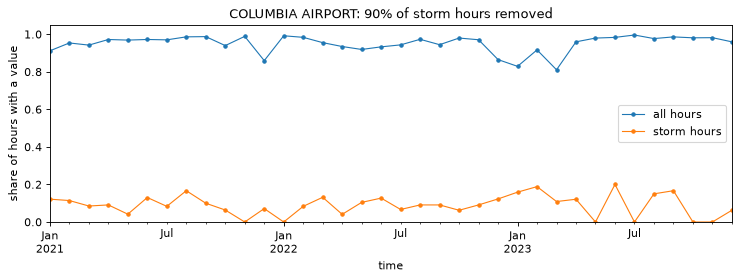

completeness 2021–2023: before 100.0%, after 95.0%
mean true temperature in storm hours 14.7 °C vs all hours 15.4 °C


In [11]:
f, s = one("storm_gaps", 0.9)
s = s[:"2023-12-31"]
month = s.index.tz_localize(None).to_period("M")
monthly = pd.DataFrame({
    "all hours": s.air_temperature.notna().groupby(month).mean(),
    "storm hours": s.air_temperature[s.storm_hour].notna().groupby(month[s.storm_hour]).mean(),
})
ax = monthly.plot(figsize=(11, 3.2), marker=".", lw=1)
ax.set(ylabel="share of hours with a value", ylim=(0, 1.05), title=f"{f['name']}: 90% of storm hours removed")
plt.show()
print(f"completeness 2021–2023: before {s.air_temperature_true.notna().mean():.1%}, after {s.air_temperature.notna().mean():.1%}")
print(f"mean true temperature in storm hours {s.air_temperature_true[s.storm_hour].mean():.1f} °C vs all hours {s.air_temperature_true.mean():.1f} °C")

Overall completeness drops from almost 100% to about 95% which would pass any completeness check you'd write. The station looks healthy. Only when completeness is split by weather do you see that it's lost almost all of its storms.

Nothing in this data is wrong. Every value that's there is correct. The problem is what's *not* there. The missing hours are a particular kind of weather (windy, wet and a bit colder than average) so the remaining data under-represents exactly the conditions where a forecast matters most.

**Why it misleads a model.** A model trained on this data sees fewer storms and fits them worse. Its average error looks fine because storms are rare and the failure only shows when you score it on the storm hours. Coverage has to be measured per weather condition and not only overall.

## Step 9 · A free physical check

Notebook 01 found that no real hour has a dew point above the air temperature. The planted faults only change the thermometer and not the humidity sensor so a fault that makes the temperature read cold can push it below the dew point which is physically impossible.

In [12]:
impossible = planted.dew_point_temperature > planted.air_temperature + 0.05
by_fault = planted[impossible].groupby("fault_id").size().rename("impossible hours")
print(catalogue.set_index("fault_id")[["name", "fault_type", "fault_size"]].join(by_fault, how="inner").to_string())
print(f"\nimpossible hours in the true data: {(planted.dew_point_temperature_true > planted.air_temperature_true + 0.05).sum()}")

                                          name fault_type  fault_size  impossible hours
fault_id                                                                               
1                    SALINAS MUNICIPAL AIRPORT      drift        -3.0               625
2                STOCKTON METROPOLITAN AIRPORT       bias        -1.0              1038
7                    REDDING MUNICIPAL AIRPORT       bias        -2.0              2547
9                  BICYCLE LAKE FORT IRWIN AAF       bias        -3.0               472
16                         GNOSS FIELD AIRPORT       step        -2.0              3915
22        NORTH AUXILIARY AIRFIELD EDWARDS AFB       step        -0.5                71
23                      EDWARDS AIR FORCE BASE       step        -0.5                71
24                     SACRAMENTO INTL AIRPORT      drift        -2.0                15

impossible hours in the true data: 0


Only cold faults show up here and how often depends on how humid the station is. A big cold fault at a humid valley airport trips it thousands of times and a small one at a dry desert base barely at all. A warm fault can never trigger it. So this check is a strong second witness when it fires and silent the rest of the time. Its recall depends on the sign of the fault. Checks with that kind of blind spot are normal. It's why notebook 05 layers several checks and doesn't rely on any one.

## Step 10 · Save it

The planted data, the catalogue, the baseline stats and the held-out list go to `data/faults/seed=0/`. Notebooks 05 and 09 read them from there.

In [13]:
out = fl.save(DATA_DIR, planted, catalogue.drop(columns="name"), stats, holdout, seed=0)
sizes = {p.name: f"{p.stat().st_size / 1e6:.0f} MB" for p in out.iterdir()}
print(out, sizes)
summary = planted[planted.is_faulty].groupby("fault_type").agg(faulty_hours=("is_faulty", "size"))
summary["share of all hours"] = (summary.faulty_hours / len(planted)).map("{:.2%}".format)
summary

/Users/ashu/Workspace/weather-data-lab/data/faults/seed=0 {'holdout.parquet': '0 MB', 'catalogue.parquet': '0 MB', 'planted.parquet': '175 MB', 'baseline.parquet': '0 MB'}


,faulty_hours,share of all hours
fault_type,,
bias,127442,3.46%
drift,39432,1.07%
step,56783,1.54%
storm_gaps,3124,0.08%
stuck,241,0.01%
time_offset,21678,0.59%


## Step 11 · One seed isn't enough

There are 27 faulty stations across six types and up to eight sizes each so each type and size gets one or two examples at most. A recall curve from that would mostly be noise. The fix is cheap because `fl.make` takes a few seconds. Notebook 05 will rerun planting with many seeds, run the checks on each and average. Each seed picks different stations, dates and sizes while the proportion of faulty stations stays realistic every time.

The table below counts how many faults of each type and size 20 seeds produce.

In [14]:
ids = stats.index[stats.baseline].tolist()
plans = pd.concat([fl.plan_faults(ids, holdout, seed=k) for k in range(20)])
counts = plans.groupby(["fault_type", "fault_size"]).size()
counts.groupby(level=0).apply(lambda c: "   ".join(f"{size:g} → {n}" for (_, size), n in c.items())).rename("size → number of faults").to_frame()

,size → number of faults
fault_type,
bias,-3 → 18 -2 → 14 -1 → 9 -0.5 → 12 0.5 →...
drift,-3 → 13 -2 → 15 -1 → 10 -0.5 → 12 0.5 ...
step,-3 → 18 -2 → 17 -1 → 11 -0.5 → 12 0.5 ...
storm_gaps,0.3 → 10 0.5 → 20 0.7 → 16 0.9 → 34
stuck,6 → 23 24 → 14 72 → 20 168 → 23
time_offset,1 → 25 3 → 29 8 → 26


Twenty seeds give between about eight and thirty examples of every type and size. That's enough for a recall curve with honest error bars. Seed 0 stays the canonical dataset for the verdicts in notebook 05 and the model experiment in notebook 09.

## What I learned

- **Recall needs planted faults.** It's the share of faults a check catches and only an answer key lists the ones nobody noticed. Planting in about a quarter of the stations leaves healthy ones for measuring false alarms.
- **Faults hide in different places.** A 1 °C step vanishes in raw temperatures and becomes a clean jump once HRRR is subtracted. An eight-hour clock error leaves the average untouched while single hours are off by 10 °C.
- **A constant bias is close to invisible.** It sits inside the range of honest offsets between a station and the model.
- **Completeness hides what's missing.** A station can lose 90% of its storms and still be 95% complete so coverage has to be measured per weather condition.
- **Healthy stations sometimes look stuck.** Whole-degree sensors on quiet nights repeat one value for half a day and short stuck faults blend in.

**Still open:** the fault sizes come from published studies of US station networks. Do faults in other kinds of sensors look anything like these?